# Experiment 04: Regularization

Card: [exp04_regularization.md](../../experiments/exp04_regularization.md)


In [1]:
import os
import sys
from time import strftime

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
from ashrae.config import FOLDS, MLFLOW_URI
from ashrae.tuning import make_folds, run_trial

SMOKE = os.environ.get("SMOKE") == "1"
LEARNING_RATE = 0.1
VARIANTS = {
    "min_child_samples 100": {"min_child_samples": 100},
    "min_child_samples 500": {"min_child_samples": 500},
    "colsample_bytree 0.8": {"colsample_bytree": 0.8},
    "smoother building categories": {"cat_smooth": 50, "min_data_per_group": 500},
    "finer building categories": {"max_cat_threshold": 128},
}
if SMOKE:
    EXPERIMENT = "ashrae-baseline-tuning-smoke"
    TRAIN = True
    FOLD_NAMES = list(FOLDS)[:2]
    N_TRAIN, N_VAL = 20_000, 5_000
    BASE_LEAVES = 15
    VARIANTS = dict(list(VARIANTS.items())[:2])
    MAX_TREES, PATIENCE, CURVE_EVERY = 60, 10, 10
    FIGURE = None
else:
    EXPERIMENT = "ashrae-baseline-tuning"
    TRAIN = False  # Stage B already ran before the split; True retrains it and its base under a new session
    FOLD_NAMES = list(FOLDS)
    N_TRAIN, N_VAL = 2_000_000, 500_000  # exp02: more rows don't help
    BASE_LEAVES = 127  # exp03: sizes are within noise, and 127 leaves room under MAX_TREES for slower settings
    MAX_TREES, PATIENCE, CURVE_EVERY = (
        5000,
        200,
        10,
    )  # every 10th tree of each validation curve goes to MLflow
    FIGURE = "../../figures/exp04_regularization.png"
SESSION = strftime("%Y-%m-%d %H:%M:%S") if TRAIN else "2026-10-11 12:25:43"
BASE = f"{BASE_LEAVES} leaves"
TRIALS = [BASE, *(f"{BASE} + {name}" for name in VARIANTS)]

mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(EXPERIMENT)
client = mlflow.MlflowClient()

/Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Trials


In [2]:
if TRAIN:
    folds = make_folds({f: FOLDS[f] for f in FOLD_NAMES}, N_TRAIN, N_VAL)
    common = {
        "learning_rate": LEARNING_RATE,
        "max_trees": MAX_TREES,
        "patience": PATIENCE,
        "curve_every": CURVE_EVERY,
        "logged": {"n_train": N_TRAIN, "n_val": N_VAL},
    }
    tags = {
        "session": SESSION,
        "model": "lgbm_building",
        "notebook": "exp04_regularization",
    }
    # The base is a Stage A trial, so it is tagged like exp03's runs
    run_trial(
        BASE, {"num_leaves": BASE_LEAVES}, folds, **common, tags={**tags, "stage": "A"}
    )
    for name, change in VARIANTS.items():
        run_trial(
            f"{BASE} + {name}",
            {"num_leaves": BASE_LEAVES, **change},
            folds,
            **common,
            tags={**tags, "stage": "B"},
        )

## Results


tags.fold,Jan–Mar,Apr–Jun,Jul–Sep,Oct–Dec,average,minus_base,trees
"RMSLE, all rows",,,,,,,
127 leaves (base),1.4038,1.2002,1.0274,1.0927,1.1810,0.0000,1736
min_child_samples 100,1.4019,1.1992,1.0294,1.0911,1.1804,-0.0006,1644
min_child_samples 500,1.4049,1.2042,1.0332,1.0919,1.1835,0.0025,2028
colsample_bytree 0.8,1.4056,1.2006,1.0202,1.0947,1.1803,-0.0007,2007
smoother building categories,1.4038,1.2002,1.0274,1.0927,1.1810,0.0000,1736
finer building categories,1.4038,1.2002,1.0274,1.0927,1.1810,0.0000,1736


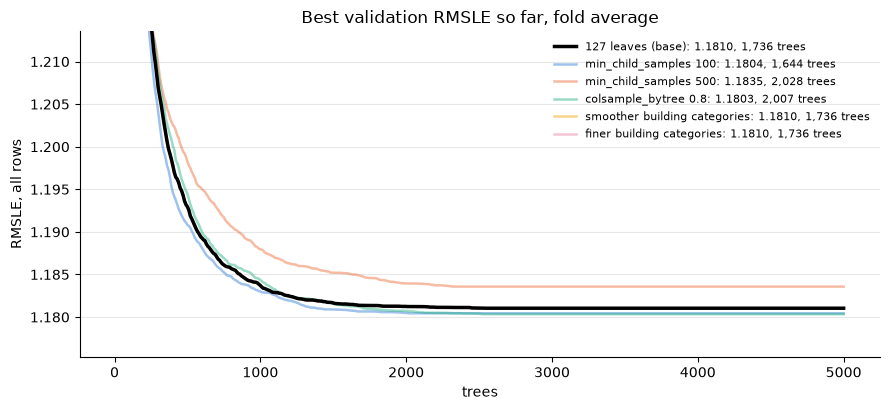

In [3]:
runs = mlflow.search_runs(
    experiment_names=[EXPERIMENT], filter_string=f"tags.session = '{SESSION}'"
)
runs = runs[runs["tags.trial"].isin(TRIALS)]
by_fold = runs.pivot(
    index="tags.trial", columns="tags.fold", values="metrics.val_rmsle"
).loc[TRIALS, FOLD_NAMES]
trees = runs.groupby("tags.trial")["metrics.trial_trees"].first()


def label(trial):
    return f"{BASE} (base)" if trial == BASE else trial.removeprefix(f"{BASE} + ")


def best_so_far(run_id):
    """Lowest validation RMSLE reached by each tree count, held flat after the fold stopped."""
    history = sorted(
        client.get_metric_history(run_id, "val_rmsle_curve_all"), key=lambda m: m.step
    )
    curve = np.full(MAX_TREES // CURVE_EVERY, np.nan)
    curve[: len(history)] = np.minimum.accumulate([m.value for m in history])
    return pd.Series(curve).ffill().to_numpy()


trees_axis = np.arange(CURVE_EVERY, MAX_TREES + 1, CURVE_EVERY)
COLORS = dict(
    zip(TRIALS, ["black", "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"])
)
fig, ax = plt.subplots(figsize=(9, 4.2))
for trial in TRIALS:
    curve = np.mean(
        [best_so_far(run_id) for run_id in runs[runs["tags.trial"] == trial].run_id],
        axis=0,
    )
    ax.plot(
        trees_axis,
        curve,
        color=COLORS[trial],
        lw=2.5 if trial == BASE else 1.8,
        alpha=1 if trial == BASE else 0.45,
        zorder=3 if trial == BASE else 2,  # base drawn on top of the variants
        label=f"{label(trial)}: {by_fold.loc[trial].mean():.4f}, {int(trees[trial]):,} trees",
    )
averages = by_fold.mean(axis=1)
ax.set(
    title="Best validation RMSLE so far, fold average",
    xlabel="trees",
    ylabel="RMSLE, all rows",
    ylim=(averages.min() - 0.005, averages.max() + 0.03),
)
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
if FIGURE:
    fig.savefig(FIGURE, dpi=150, bbox_inches="tight")
    for run_id in runs[runs["tags.stage"] == "B"].run_id:
        client.log_artifact(run_id, FIGURE)

display(
    by_fold.assign(
        average=averages,
        minus_base=averages - averages[BASE],
        trees=trees.loc[TRIALS].astype(int),
    )
    .rename(index=label)
    .round(4)
    .rename_axis("RMSLE, all rows")
)